<a href="https://colab.research.google.com/github/kandhicharanyadav/Quantum_Computing/blob/main/Product_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install "qiskit[all]~=2.5.1" matplotlib

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 62.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 75.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 13.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.6/49.6 MB 7.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 33.1/33.1 MB 46.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 541.5/541.5 kB 36.4 MB/s eta 0:00:00
  Created wheel for python-constraint: filename=python_constraint-1.4.0-py2.py3-none-any.whl size=24061 sha256=f6c3120f6645a327cd94239e674fd7964f4eea181b9d65bdca485fd9a6017646
  Stored in directory: /root/.cache/pip/wheels/f4/b8/c6/1f1e3b56069cb07de800d72df63b47af5ca79bbad5b8952f70
Successfully built python-constraint


In [2]:
import qiskit

print(qiskit.__version__)

2.5.2


In [3]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

qc = QuantumCircuit(1)
qc.h(0)

state = Statevector.from_instruction(qc)

print(qc)
print(state)
print(state.probabilities_dict())

   ┌───┐
q: ┤ H ├
   └───┘
Statevector([0.70710678+0.j, 0.70710678+0.j],
            dims=(2,))
{np.str_('0'): np.float64(0.4999999999999999), np.str_('1'): np.float64(0.4999999999999999)}


In [4]:
from math import pi
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from qiskit.primitives import StatevectorSampler
from qiskit.visualization import plot_histogram

def simulate_ideal(circuit, shots=1024, seed=7):
    # Exact state before measurement
    state = Statevector.from_instruction(circuit)

    # Make a separate copy for measurement
    measured = circuit.copy()
    measured.measure_all()

    # Sample measurement outcomes
    result = (
        StatevectorSampler(seed=seed)
        .run([measured], shots=shots)
        .result()[0]
    )

    counts = result.data.meas.get_counts()

    return state, counts

Circuit:
   ┌───┐
q: ┤ H ├
   └───┘

Statevector:
Statevector([0.70710678+0.j, 0.70710678+0.j],
            dims=(2,))

Probabilities:
{np.str_('0'): np.float64(0.4999999999999999), np.str_('1'): np.float64(0.4999999999999999)}

Measurement counts:
{'1': 507, '0': 517}


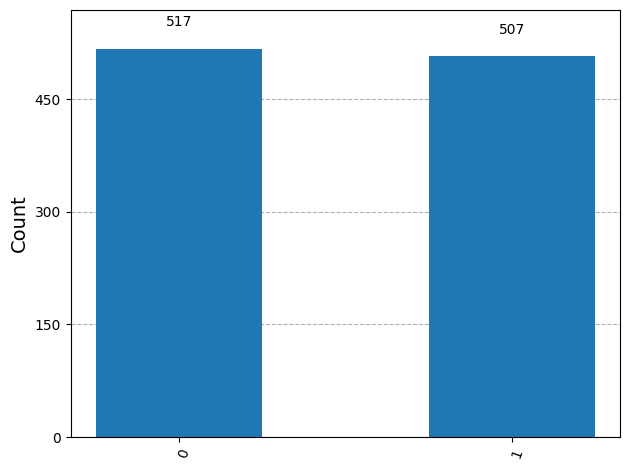

In [5]:
qc = QuantumCircuit(1)
qc.h(0)

state, counts = simulate_ideal(qc, shots=1024)

print("Circuit:")
print(qc)

print("\nStatevector:")
print(state)

print("\nProbabilities:")
print(state.probabilities_dict())

print("\nMeasurement counts:")
print(counts)

plot_histogram(counts)

Circuit:
   ┌───┐
q: ┤ X ├
   └───┘

Statevector:
Statevector([0.+0.j, 1.+0.j],
            dims=(2,))

Probabilities:
{np.str_('1'): np.float64(1.0)}

Measurement counts:
{'1': 1024}


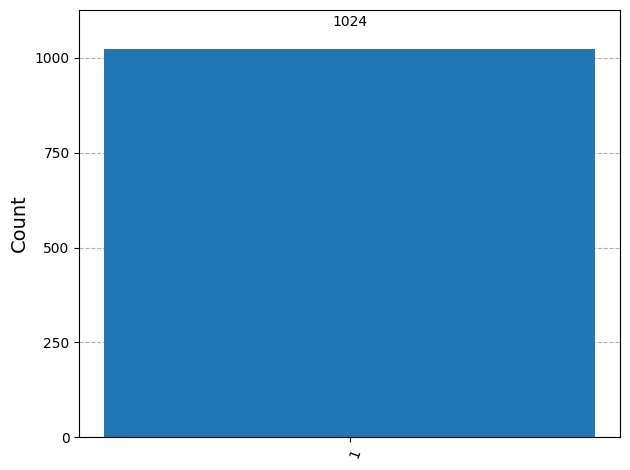

In [6]:
qc = QuantumCircuit(1)

# Apply X gate
qc.x(0)

state, counts = simulate_ideal(qc, shots=1024)

print("Circuit:")
print(qc)

print("\nStatevector:")
print(state)

print("\nProbabilities:")
print(state.probabilities_dict())

print("\nMeasurement counts:")
print(counts)

plot_histogram(counts)

Circuit:
   ┌───┐
q: ┤ Y ├
   └───┘

Statevector:
Statevector([0.+0.j, 0.+1.j],
            dims=(2,))

Probabilities:
{np.str_('1'): np.float64(1.0)}

Measurement counts:
{'1': 1024}


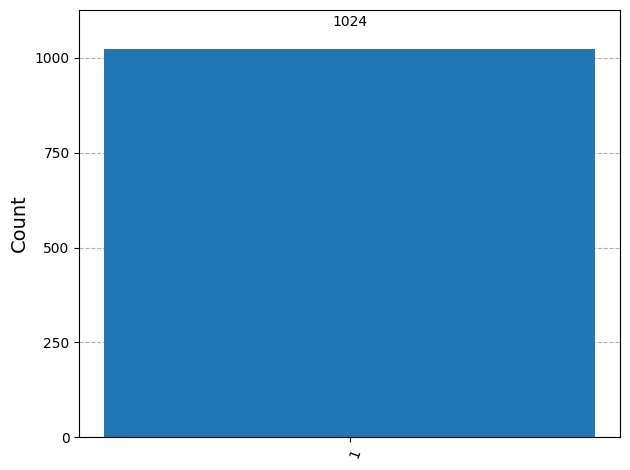

In [7]:
qc = QuantumCircuit(1)

# Apply Y gate
qc.y(0)

state, counts = simulate_ideal(qc, shots=1024)

print("Circuit:")
print(qc)

print("\nStatevector:")
print(state)

print("\nProbabilities:")
print(state.probabilities_dict())

print("\nMeasurement counts:")
print(counts)

plot_histogram(counts)

Circuit:
   ┌───┐┌───┐
q: ┤ H ├┤ Z ├
   └───┘└───┘

Statevector:
Statevector([ 0.70710678+0.j, -0.70710678+0.j],
            dims=(2,))

Probabilities:
{np.str_('0'): np.float64(0.4999999999999999), np.str_('1'): np.float64(0.4999999999999999)}

Measurement counts:
{'1': 507, '0': 517}


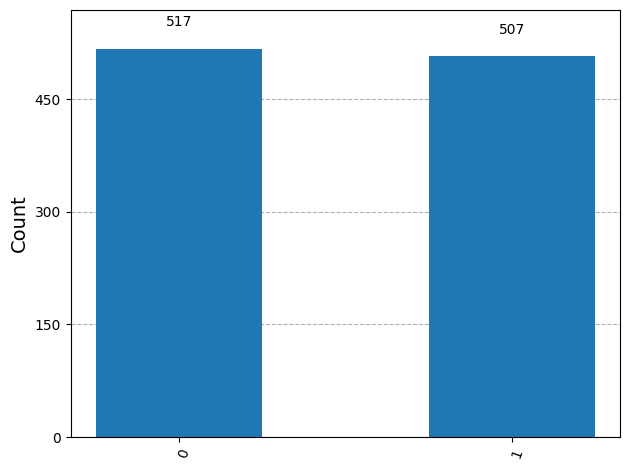

In [8]:
qc = QuantumCircuit(1)

# Prepare |+>
qc.h(0)

# Apply Z gate
qc.z(0)

state, counts = simulate_ideal(qc, shots=1024)

print("Circuit:")
print(qc)

print("\nStatevector:")
print(state)

print("\nProbabilities:")
print(state.probabilities_dict())

print("\nMeasurement counts:")
print(counts)

plot_histogram(counts)

Circuit:
   ┌───┐
q: ┤ H ├
   └───┘

Statevector:
Statevector([0.70710678+0.j, 0.70710678+0.j],
            dims=(2,))

Probabilities:
{np.str_('0'): np.float64(0.4999999999999999), np.str_('1'): np.float64(0.4999999999999999)}

Measurement counts:
{'1': 507, '0': 517}


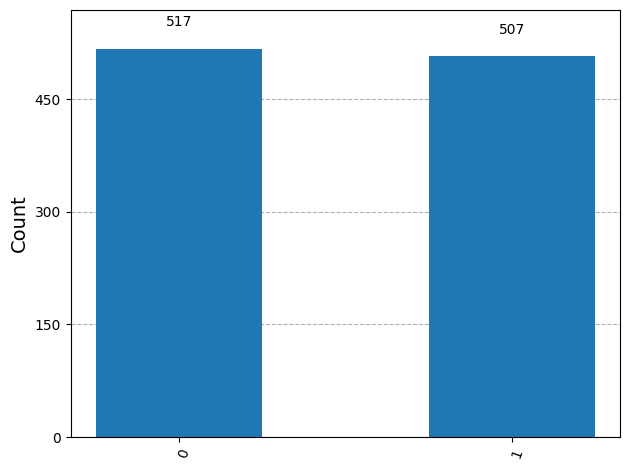

In [9]:
from qiskit.visualization import plot_bloch_multivector

qc = QuantumCircuit(1)

# Apply Hadamard
qc.h(0)

state, counts = simulate_ideal(qc, shots=1024)

print("Circuit:")
print(qc)

print("\nStatevector:")
print(state)

print("\nProbabilities:")
print(state.probabilities_dict())

print("\nMeasurement counts:")
print(counts)

plot_histogram(counts)

Circuit:
   ┌───┐┌───┐
q: ┤ H ├┤ S ├
   └───┘└───┘

Statevector:
Statevector([0.70710678+0.j        , 0.        +0.70710678j],
            dims=(2,))

Probabilities:
{np.str_('0'): np.float64(0.4999999999999999), np.str_('1'): np.float64(0.4999999999999999)}

Measurement counts:
{'1': 507, '0': 517}


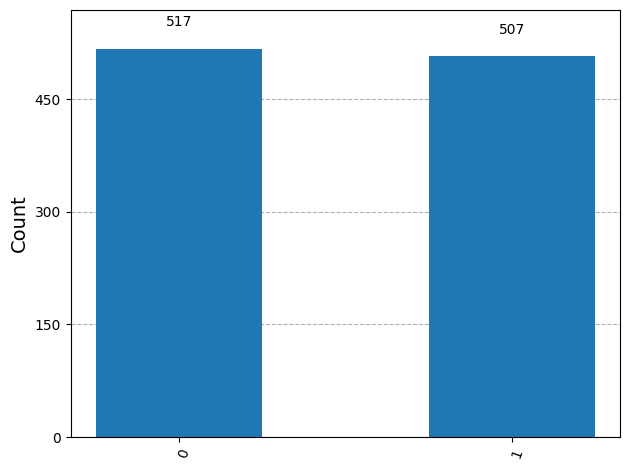

In [10]:
qc = QuantumCircuit(1)

# Prepare |+>
qc.h(0)

# Apply Phase-S gate
qc.s(0)

state, counts = simulate_ideal(qc, shots=1024)

print("Circuit:")
print(qc)

print("\nStatevector:")
print(state)

print("\nProbabilities:")
print(state.probabilities_dict())

print("\nMeasurement counts:")
print(counts)

plot_histogram(counts)

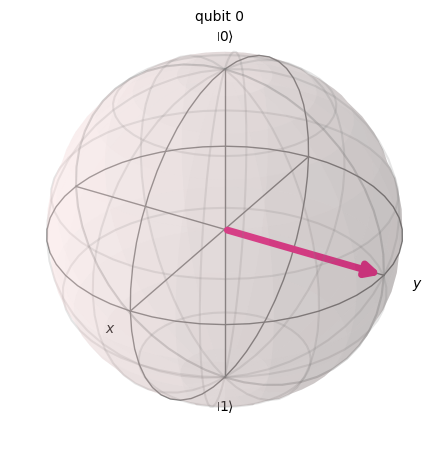

In [11]:
plot_bloch_multivector(state)

Circuit:
   ┌───┐┌───┐
q: ┤ H ├┤ T ├
   └───┘└───┘

Statevector:
Statevector([0.70710678+0.j , 0.5       +0.5j],
            dims=(2,))

Probabilities:
{np.str_('0'): np.float64(0.4999999999999999), np.str_('1'): np.float64(0.4999999999999999)}

Measurement counts:
{'1': 507, '0': 517}


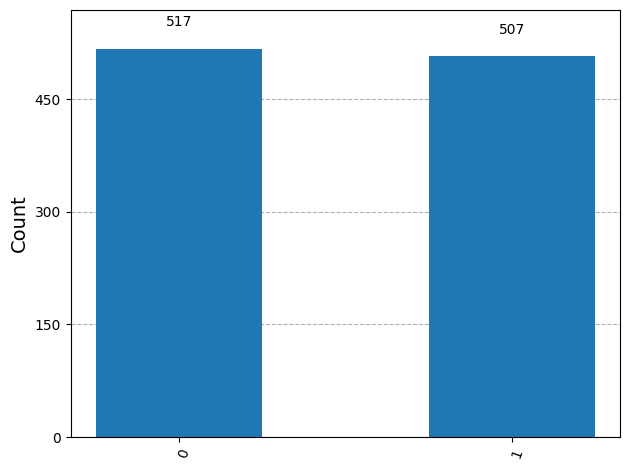

In [12]:
qc = QuantumCircuit(1)

# Prepare |+>
qc.h(0)

# Apply Phase-T gate
qc.t(0)

state, counts = simulate_ideal(qc, shots=1024)

print("Circuit:")
print(qc)

print("\nStatevector:")
print(state)

print("\nProbabilities:")
print(state.probabilities_dict())

print("\nMeasurement counts:")
print(counts)

plot_histogram(counts)

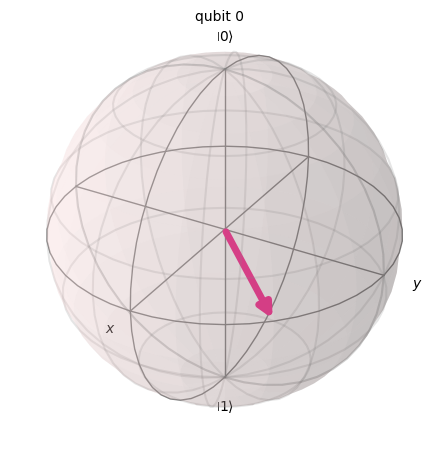

In [13]:
plot_bloch_multivector(state)

Circuit:
   ┌─────────┐
q: ┤ Rx(π/2) ├
   └─────────┘

Statevector:
Statevector([0.70710678+0.j        , 0.        -0.70710678j],
            dims=(2,))

Probabilities:
{np.str_('0'): np.float64(0.5000000000000001), np.str_('1'): np.float64(0.4999999999999999)}

Measurement counts:
{'1': 507, '0': 517}


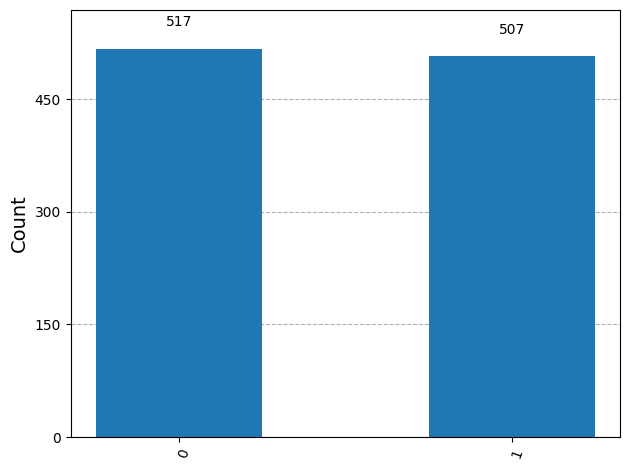

In [14]:
from math import pi

theta = pi / 2

qc = QuantumCircuit(1)

# Apply Rx(pi/2)
qc.rx(theta, 0)

state, counts = simulate_ideal(qc, shots=1024)

print("Circuit:")
print(qc)

print("\nStatevector:")
print(state)

print("\nProbabilities:")
print(state.probabilities_dict())

print("\nMeasurement counts:")
print(counts)

plot_histogram(counts)

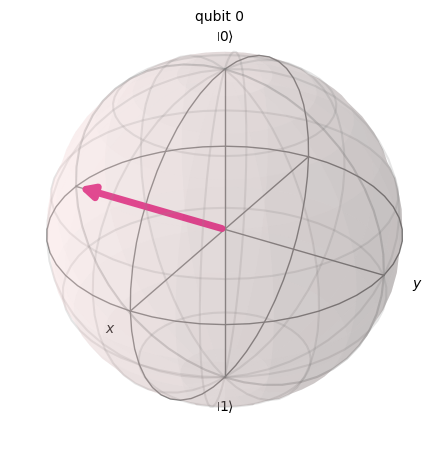

In [15]:
plot_bloch_multivector(state)

Circuit:
   ┌─────────┐
q: ┤ Ry(π/2) ├
   └─────────┘

Statevector:
Statevector([0.70710678+0.j, 0.70710678+0.j],
            dims=(2,))

Probabilities:
{np.str_('0'): np.float64(0.5000000000000001), np.str_('1'): np.float64(0.4999999999999999)}

Measurement counts:
{'1': 507, '0': 517}


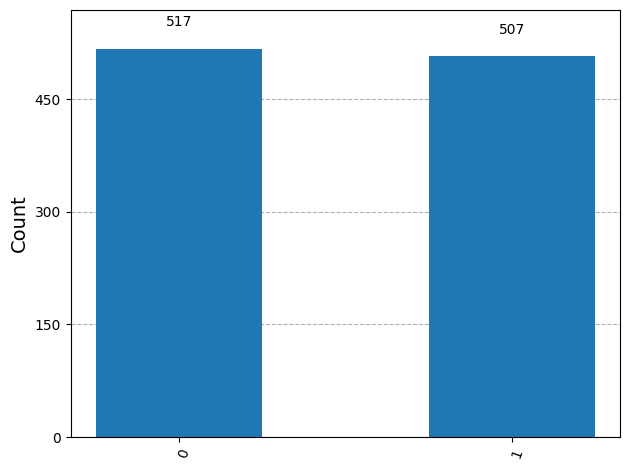

In [16]:
theta = pi / 2

qc = QuantumCircuit(1)

# Apply Ry(pi/2)
qc.ry(theta, 0)

state, counts = simulate_ideal(qc, shots=1024)

print("Circuit:")
print(qc)

print("\nStatevector:")
print(state)

print("\nProbabilities:")
print(state.probabilities_dict())

print("\nMeasurement counts:")
print(counts)

plot_histogram(counts)

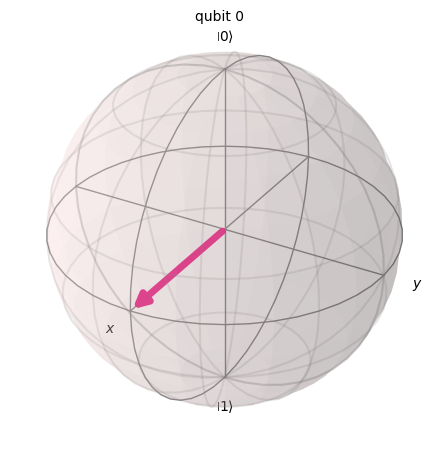

In [17]:
plot_bloch_multivector(state)

Circuit:
   ┌───┐┌─────────┐
q: ┤ H ├┤ Rz(π/2) ├
   └───┘└─────────┘

Statevector:
Statevector([0.5-0.5j, 0.5+0.5j],
            dims=(2,))

Probabilities:
{np.str_('0'): np.float64(0.4999999999999999), np.str_('1'): np.float64(0.4999999999999999)}

Measurement counts:
{'1': 507, '0': 517}


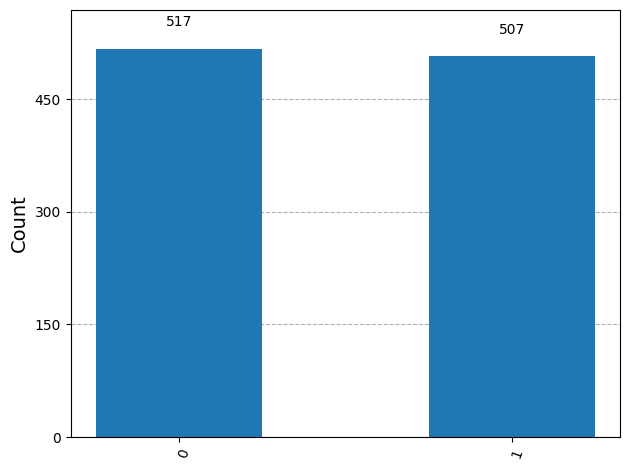

In [18]:
theta = pi / 2

qc = QuantumCircuit(1)

# Prepare |+> so the phase rotation is observable
qc.h(0)

# Apply Rz(pi/2)
qc.rz(theta, 0)

state, counts = simulate_ideal(qc, shots=1024)

print("Circuit:")
print(qc)

print("\nStatevector:")
print(state)

print("\nProbabilities:")
print(state.probabilities_dict())

print("\nMeasurement counts:")
print(counts)

plot_histogram(counts)

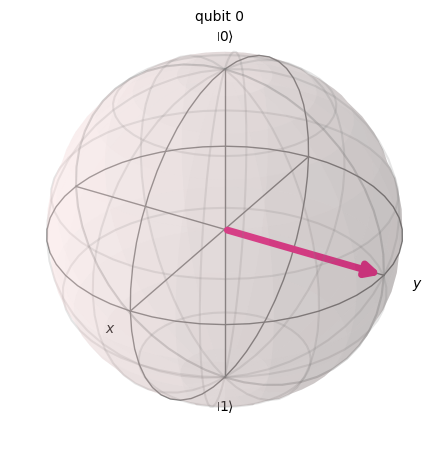

In [19]:
plot_bloch_multivector(state)

Circuit:
   ┌───┐
q: ┤ H ├
   └───┘

State BEFORE measurement:
Statevector([0.70710678+0.j, 0.70710678+0.j],
            dims=(2,))

Exact probabilities:
{np.str_('0'): np.float64(0.4999999999999999), np.str_('1'): np.float64(0.4999999999999999)}

Measurement counts:
{'1': 507, '0': 517}


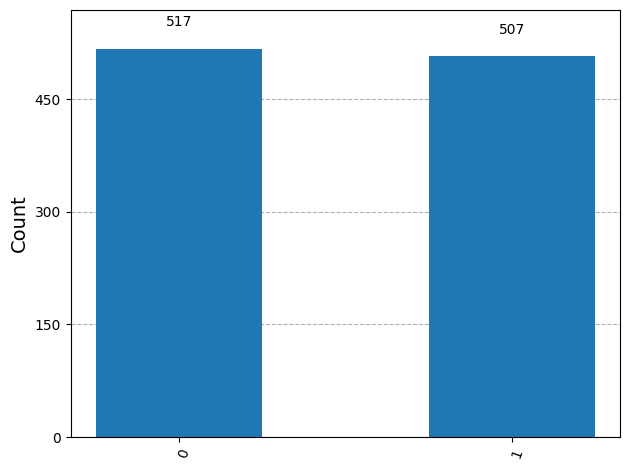

In [20]:
qc = QuantumCircuit(1)

# Prepare |+>
qc.h(0)

# Simulate measurement
state, counts = simulate_ideal(qc, shots=1024)

print("Circuit:")
print(qc)

print("\nState BEFORE measurement:")
print(state)

print("\nExact probabilities:")
print(state.probabilities_dict())

print("\nMeasurement counts:")
print(counts)

plot_histogram(counts)

Circuit:
     ┌───┐     
q_0: ┤ X ├──■──
     └───┘┌─┴─┐
q_1: ─────┤ X ├
          └───┘

Statevector:
Statevector([0.+0.j, 0.+0.j, 0.+0.j, 1.+0.j],
            dims=(2, 2))

Probabilities:
{np.str_('11'): np.float64(1.0)}

Measurement counts:
{'11': 1024}


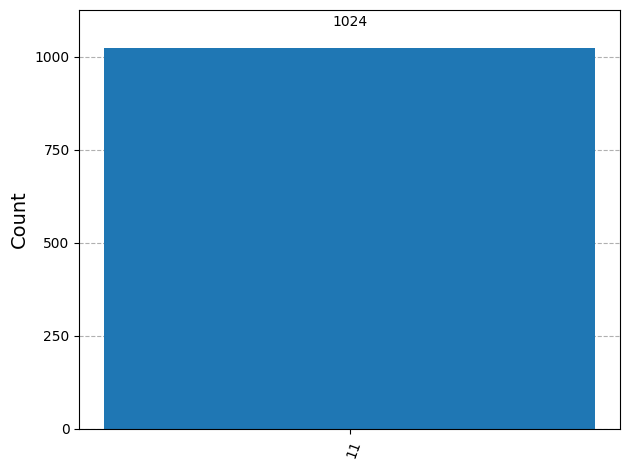

In [21]:
qc = QuantumCircuit(2)

# Prepare q0 = |1>
qc.x(0)

# CNOT: q0 controls q1
qc.cx(0, 1)

state, counts = simulate_ideal(qc, shots=1024)

print("Circuit:")
print(qc)

print("\nStatevector:")
print(state)

print("\nProbabilities:")
print(state.probabilities_dict())

print("\nMeasurement counts:")
print(counts)

plot_histogram(counts)

Circuit:
     ┌───┐   
q_0: ┤ H ├─■─
     ├───┤ │ 
q_1: ┤ H ├─■─
     └───┘   

Statevector:
Statevector([ 0.5+0.j,  0.5+0.j,  0.5+0.j, -0.5+0.j],
            dims=(2, 2))

Probabilities:
{np.str_('00'): np.float64(0.2499999999999999), np.str_('01'): np.float64(0.2499999999999999), np.str_('10'): np.float64(0.2499999999999999), np.str_('11'): np.float64(0.2499999999999999)}

Measurement counts:
{'10': 250, '11': 257, '00': 265, '01': 252}


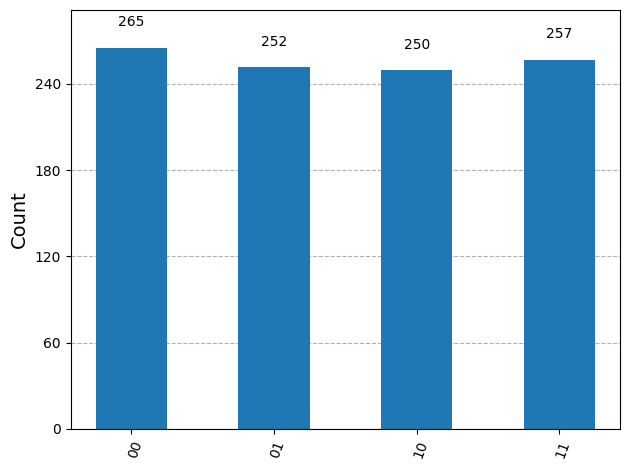

In [22]:
qc = QuantumCircuit(2)

# Prepare |++>
qc.h(0)
qc.h(1)

# Apply Controlled-Z
qc.cz(0, 1)

state, counts = simulate_ideal(qc, shots=1024)

print("Circuit:")
print(qc)

print("\nStatevector:")
print(state)

print("\nProbabilities:")
print(state.probabilities_dict())

print("\nMeasurement counts:")
print(counts)

plot_histogram(counts)

Circuit:
     ┌───┐   
q_0: ┤ X ├─X─
     └───┘ │ 
q_1: ──────X─
             

Statevector:
Statevector([0.+0.j, 0.+0.j, 1.+0.j, 0.+0.j],
            dims=(2, 2))

Probabilities:
{np.str_('10'): np.float64(1.0)}

Measurement counts:
{'10': 1024}


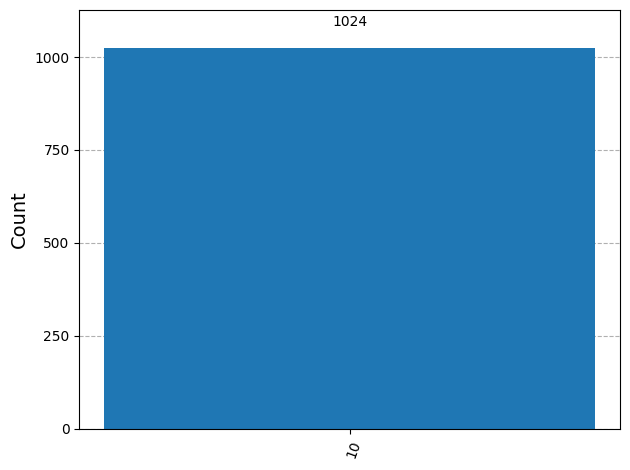

In [23]:
qc = QuantumCircuit(2)

# Put q0 in |1>
qc.x(0)

# Swap q0 and q1
qc.swap(0, 1)

state, counts = simulate_ideal(qc, shots=1024)

print("Circuit:")
print(qc)

print("\nStatevector:")
print(state)

print("\nProbabilities:")
print(state.probabilities_dict())

print("\nMeasurement counts:")
print(counts)

plot_histogram(counts)

Circuit:
     ┌───┐     
q_0: ┤ X ├──■──
     ├───┤  │  
q_1: ┤ X ├──■──
     └───┘┌─┴─┐
q_2: ─────┤ X ├
          └───┘

Statevector:
Statevector([0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j,
             1.+0.j],
            dims=(2, 2, 2))

Probabilities:
{np.str_('111'): np.float64(1.0)}

Measurement counts:
{'111': 1024}


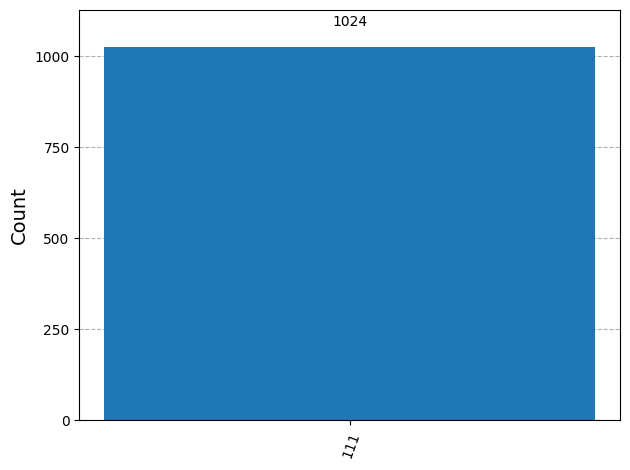

In [24]:
qc = QuantumCircuit(3)

# Set both control qubits to |1>
qc.x(0)
qc.x(1)

# Toffoli: q0 and q1 control q2
qc.ccx(0, 1, 2)

state, counts = simulate_ideal(qc, shots=1024)

print("Circuit:")
print(qc)

print("\nStatevector:")
print(state)

print("\nProbabilities:")
print(state.probabilities_dict())

print("\nMeasurement counts:")
print(counts)

plot_histogram(counts)

Circuit:
     ┌───┐     
q_0: ┤ H ├──■──
     └───┘┌─┴─┐
q_1: ─────┤ X ├
          └───┘

Statevector:
Statevector([0.70710678+0.j, 0.        +0.j, 0.        +0.j,
             0.70710678+0.j],
            dims=(2, 2))

Probabilities:
{np.str_('00'): np.float64(0.4999999999999999), np.str_('11'): np.float64(0.4999999999999999)}

Measurement counts:
{'11': 507, '00': 517}


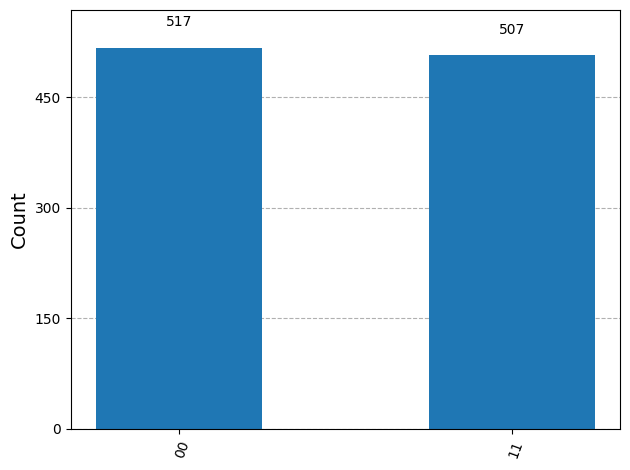

In [25]:
qc = QuantumCircuit(2)

# Create Bell state
qc.h(0)
qc.cx(0, 1)

state, counts = simulate_ideal(qc, shots=1024)

print("Circuit:")
print(qc)

print("\nStatevector:")
print(state)

print("\nProbabilities:")
print(state.probabilities_dict())

print("\nMeasurement counts:")
print(counts)

plot_histogram(counts)

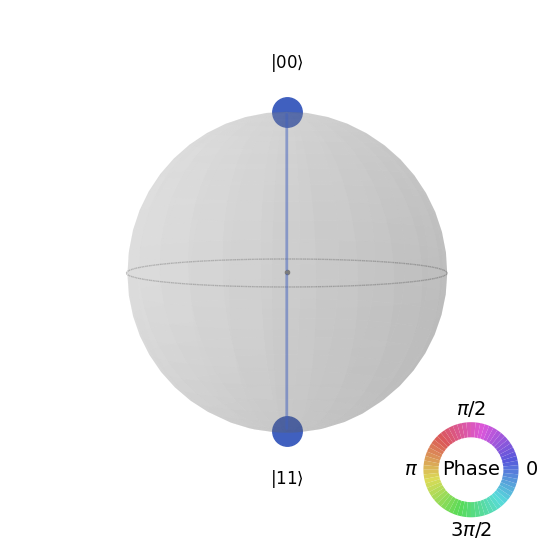

In [26]:
from qiskit.visualization import plot_state_qsphere

plot_state_qsphere(state)

Circuit:
     ┌───┐          
q_0: ┤ H ├──■────■──
     └───┘┌─┴─┐  │  
q_1: ─────┤ X ├──┼──
          └───┘┌─┴─┐
q_2: ──────────┤ X ├
               └───┘

Statevector:
Statevector([0.70710678+0.j, 0.        +0.j, 0.        +0.j,
             0.        +0.j, 0.        +0.j, 0.        +0.j,
             0.        +0.j, 0.70710678+0.j],
            dims=(2, 2, 2))

Probabilities:
{np.str_('000'): np.float64(0.4999999999999999), np.str_('111'): np.float64(0.4999999999999999)}

Measurement counts:
{'111': 507, '000': 517}


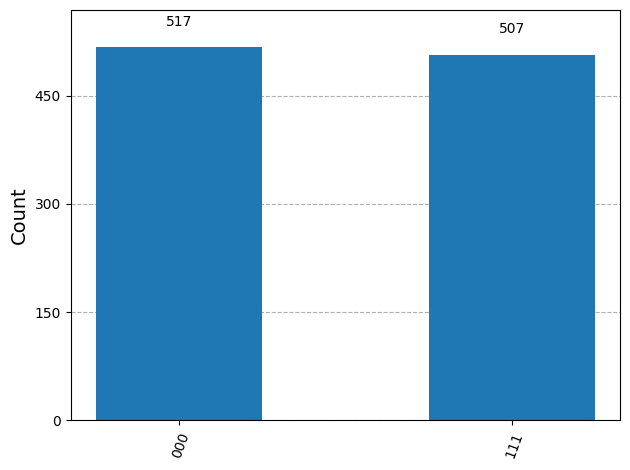

In [27]:
qc = QuantumCircuit(3)

# Create GHZ state
qc.h(0)
qc.cx(0, 1)
qc.cx(0, 2)

state, counts = simulate_ideal(qc, shots=1024)

print("Circuit:")
print(qc)

print("\nStatevector:")
print(state)

print("\nProbabilities:")
print(state.probabilities_dict())

print("\nMeasurement counts:")
print(counts)

plot_histogram(counts)

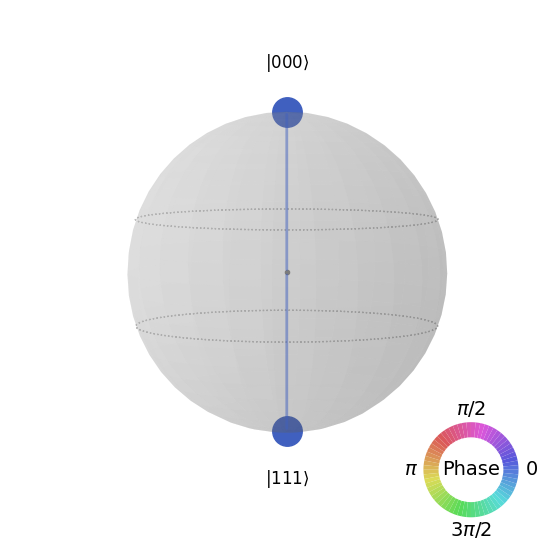

In [28]:
plot_state_qsphere(state)

In [29]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from qiskit.primitives import StatevectorSampler

# Create a 1-qubit circuit
qc = QuantumCircuit(1)

# Apply Identity gate
qc.id(0)

# Display circuit
print(qc.draw())

# Get exact pre-measurement state
state = Statevector.from_instruction(qc)

print("\nStatevector:")
print(state.data)

print("\nProbabilities:")
print(state.probabilities_dict())

# Create a separate measured circuit
measured = qc.copy()
measured.measure_all()

# Simulate 1024 shots
result = (
    StatevectorSampler(seed=7)
    .run([measured], shots=1024)
    .result()[0]
)

counts = result.data.meas.get_counts()

print("\nMeasurement counts:")
print(counts)

   ┌───┐
q: ┤ I ├
   └───┘

Statevector:
[1.+0.j 0.+0.j]

Probabilities:
{np.str_('0'): np.float64(1.0)}

Measurement counts:
{'0': 1024}


In [30]:
# Create |+> = H|0>
qc2 = QuantumCircuit(1)
qc2.h(0)
qc2.id(0)

state2 = Statevector.from_instruction(qc2)

print("Circuit:")
print(qc2.draw())

print("\nStatevector after H then I:")
print(state2.data)

print("\nProbabilities:")
print(state2.probabilities_dict())

Circuit:
   ┌───┐┌───┐
q: ┤ H ├┤ I ├
   └───┘└───┘

Statevector after H then I:
[0.70710678+0.j 0.70710678+0.j]

Probabilities:
{np.str_('0'): np.float64(0.4999999999999999), np.str_('1'): np.float64(0.4999999999999999)}


In [31]:
from math import isclose
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector


def probabilities(circuit):
    return Statevector.from_instruction(circuit).probabilities_dict()


# Test 1: X gate
x = QuantumCircuit(1)
x.x(0)

p = probabilities(x)

assert isclose(float(p.get('1', 0)), 1.0)

print("✅ X test passed")


# Test 2: Bell state
bell = QuantumCircuit(2)
bell.h(0)
bell.cx(0, 1)

p = probabilities(bell)

assert set(p) == {'00', '11'}
assert isclose(float(p['00']), 0.5, abs_tol=1e-12)
assert isclose(float(p['11']), 0.5, abs_tol=1e-12)

print("✅ Bell test passed")


# Test 3: GHZ state
ghz = QuantumCircuit(3)
ghz.h(0)
ghz.cx(0, 1)
ghz.cx(0, 2)

p = probabilities(ghz)

assert set(p) == {'000', '111'}
assert isclose(float(p['000']), 0.5, abs_tol=1e-12)
assert isclose(float(p['111']), 0.5, abs_tol=1e-12)

print("✅ GHZ test passed")


print("\n🎉 All automated sanity tests passed!")

✅ X test passed
✅ Bell test passed
✅ GHZ test passed

🎉 All automated sanity tests passed!


In [32]:
# ============================================================
# QUANTUM CIRCUIT DESIGNER AND SIMULATOR
# ============================================================

import math
from math import pi
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from qiskit.visualization import (
    plot_histogram,
    plot_bloch_multivector,
    plot_state_qsphere
)

from IPython.display import display, clear_output
import ipywidgets as widgets


# ------------------------------------------------------------
# Circuit list - all 17 circuits from the lab
# ------------------------------------------------------------

CIRCUITS = [
    "Identity",
    "Pauli-X",
    "Pauli-Y",
    "Pauli-Z",
    "Hadamard",
    "Phase-S",
    "Phase-T",
    "Rx",
    "Ry",
    "Rz",
    "Measurement",
    "CNOT",
    "Controlled-Z",
    "SWAP",
    "Toffoli",
    "Bell",
    "GHZ"
]


# ------------------------------------------------------------
# Build circuit
# ------------------------------------------------------------

def build_circuit(name, theta):

    # Identity
    if name == "Identity":
        qc = QuantumCircuit(1)
        qc.id(0)

    # Pauli-X
    elif name == "Pauli-X":
        qc = QuantumCircuit(1)
        qc.x(0)

    # Pauli-Y
    elif name == "Pauli-Y":
        qc = QuantumCircuit(1)
        qc.y(0)

    # Pauli-Z on |+>
    elif name == "Pauli-Z":
        qc = QuantumCircuit(1)
        qc.h(0)
        qc.z(0)

    # Hadamard
    elif name == "Hadamard":
        qc = QuantumCircuit(1)
        qc.h(0)

    # Phase-S on |+>
    elif name == "Phase-S":
        qc = QuantumCircuit(1)
        qc.h(0)
        qc.s(0)

    # Phase-T on |+>
    elif name == "Phase-T":
        qc = QuantumCircuit(1)
        qc.h(0)
        qc.t(0)

    # Rx
    elif name == "Rx":
        qc = QuantumCircuit(1)
        qc.rx(theta, 0)

    # Ry
    elif name == "Ry":
        qc = QuantumCircuit(1)
        qc.ry(theta, 0)

    # Rz on |+>
    elif name == "Rz":
        qc = QuantumCircuit(1)
        qc.h(0)
        qc.rz(theta, 0)

    # Measurement demonstration
    elif name == "Measurement":
        qc = QuantumCircuit(1)
        qc.h(0)

    # CNOT demonstration
    elif name == "CNOT":
        qc = QuantumCircuit(2)
        qc.x(0)
        qc.cx(0, 1)

    # Controlled-Z on |++>
    elif name == "Controlled-Z":
        qc = QuantumCircuit(2)
        qc.h(0)
        qc.h(1)
        qc.cz(0, 1)

    # SWAP demonstration
    elif name == "SWAP":
        qc = QuantumCircuit(2)
        qc.x(0)
        qc.swap(0, 1)

    # Toffoli demonstration
    elif name == "Toffoli":
        qc = QuantumCircuit(3)
        qc.x(0)
        qc.x(1)
        qc.ccx(0, 1, 2)

    # Bell state
    elif name == "Bell":
        qc = QuantumCircuit(2)
        qc.h(0)
        qc.cx(0, 1)

    # GHZ state
    elif name == "GHZ":
        qc = QuantumCircuit(3)
        qc.h(0)
        qc.cx(0, 1)
        qc.cx(0, 2)

    else:
        raise ValueError("Unknown circuit")

    return qc


# ------------------------------------------------------------
# Simulation
# ------------------------------------------------------------

def simulate_designer(circuit, shots=1024, seed=7):

    # Exact state BEFORE measurement
    state = Statevector.from_instruction(circuit)

    # Separate copy for measurement
    measured = circuit.copy()
    measured.measure_all()

    result = (
        StatevectorSampler(seed=seed)
        .run([measured], shots=shots)
        .result()[0]
    )

    counts = result.data.meas.get_counts()

    return state, measured, counts


# ------------------------------------------------------------
# Draw application output
# ------------------------------------------------------------

def run_designer(name, theta, shots):

    clear_output(wait=True)

    print("⚛️ QUANTUM CIRCUIT DESIGNER AND SIMULATOR")
    print("=" * 55)
    print(f"Circuit: {name}")
    print(f"θ: {theta:.4f} radians ({theta/pi:.2f}π)")
    print(f"Shots: {shots}")
    print()

    # Build circuit
    circuit = build_circuit(name, theta)

    # Simulate
    state, measured, counts = simulate_designer(
        circuit,
        shots=shots,
        seed=7
    )

    # --------------------------------------------------------
    # Circuit diagrams
    # --------------------------------------------------------

    print("UNITARY CIRCUIT")
    display(circuit.draw("mpl"))

    print("\nMEASURED CIRCUIT")
    display(measured.draw("mpl"))

    # --------------------------------------------------------
    # State information
    # --------------------------------------------------------

    print("\n" + "=" * 55)
    print("STATE BEFORE MEASUREMENT")
    print("=" * 55)

    print(state.data)

    print("\nIDEAL PROBABILITIES")
    print(state.probabilities_dict())

    print("\nSAMPLED MEASUREMENT COUNTS")
    print(counts)

    # --------------------------------------------------------
    # Histogram
    # --------------------------------------------------------

    print("\nMEASUREMENT HISTOGRAM")

    fig = plot_histogram(
        counts,
        figsize=(8, 5)
    )

    display(fig)
    plt.close(fig)

    # --------------------------------------------------------
    # Visualization
    # --------------------------------------------------------

    print("\nSTATE VISUALIZATION")

    if circuit.num_qubits == 1:

        print("Bloch Sphere")

        fig = plot_bloch_multivector(state)
        display(fig)
        plt.close(fig)

    else:

        print("Q-Sphere")

        fig = plot_state_qsphere(state)
        display(fig)
        plt.close(fig)

    print("\n" + "=" * 55)
    print("ℹ️ Counts are sampled from the exact ideal probabilities.")
    print("Small differences between runs are normal.")
    print("=" * 55)


# ------------------------------------------------------------
# Interactive controls
# ------------------------------------------------------------

circuit_dropdown = widgets.Dropdown(
    options=CIRCUITS,
    value="Hadamard",
    description="Circuit:",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="350px")
)

theta_slider = widgets.FloatSlider(
    value=pi / 2,
    min=0,
    max=2 * pi,
    step=pi / 16,
    description="θ:",
    readout_format=".4f",
    continuous_update=False,
    style={"description_width": "initial"},
    layout=widgets.Layout(width="500px")
)

shots_dropdown = widgets.Dropdown(
    options=[32, 128, 512, 1024, 4096, 8192],
    value=1024,
    description="Shots:",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="300px")
)

run_button = widgets.Button(
    description="▶ Run Circuit",
    button_style="primary",
    icon="play"
)

output = widgets.Output()


def run_button_clicked(_):
    with output:
        run_designer(
            circuit_dropdown.value,
            theta_slider.value,
            shots_dropdown.value
        )


run_button.on_click(run_button_clicked)


# ------------------------------------------------------------
# Display controls
# ------------------------------------------------------------

display(
    widgets.VBox([
        widgets.HTML("<h2>⚛️ Quantum Circuit Designer</h2>"),
        circuit_dropdown,
        theta_slider,
        shots_dropdown,
        run_button,
        output
    ])
)

# Run default circuit automatically
with output:
    run_designer(
        circuit_dropdown.value,
        theta_slider.value,
        shots_dropdown.value
    )